# Would knowing the site of metabolism help?

The best arm in this project ranks ~34 rule-generated candidates and keeps five, reaching 46.6%
recall@5. Its failures are not near-misses. Across the four arms that rank the same candidate lists,
`tanimoto_wrong` stays between 0.567 and 0.584 while recall@5 moves from 16.2% to 46.6%. The
ranker turns "answer in the list, ranked low" into hits and leaves the cases where it has no
signal. Each arm's average covers a different set of failed rows (165 to 246), so this is suggestive. The generating arms sit lower (0.512 for the tuned writer) because
they return different molecules entirely.

The site of metabolism is that missing signal. Every holdout row carries one, as the parent SMILES
with an atom map on the reacting atom:

```
parent      CNCC[C@@H](Oc1ccccc1C)c1ccccc1
som_smiles  Cc1ccccc1O[C@H](CC[NH:1]C)c1ccccc1      the nitrogen
metabolite  Cc1ccccc1O[C@H](CCN)c1ccccc1            N-demethylation
```

**This is a ceiling.** The true site is not known in advance. The ceiling is
generous: the filter uses each (parent, metabolite) pair's own label, where a deployed model
predicts sites for a parent without knowing which metabolite it is aiming at. If the ceiling is
low, no site predictor is worth building. If it is high, the gain depends on how well sites can be
predicted.

## 1. Reading the site, and attributing a candidate to the atoms its rule touched

In [1]:
import json, os, pathlib, sys, collections, time
import numpy as np, pandas as pd

ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "SOM" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))
from src import evaluation as ev
from src import decoding as dec

for line in (ROOT / ".env").read_text().splitlines():
    if "=" in line and not line.startswith("#"):
        k, v = line.split("=", 1); os.environ[k.strip()] = v.strip()
import tinker
import tinker.types as tt

from rdkit import Chem, RDLogger
from rdkit.Chem import AllChem
RDLogger.DisableLog("rdApp.*")

rules = pd.read_csv(ROOT / "rules" / "metabolism_rules.csv")
COMPILED = []
for _, r in rules.iterrows():
    rxn = AllChem.ReactionFromSmarts(r["smirks"]); rxn.Initialize()
    COMPILED.append((rxn, bool(r["keep_largest_fragment"])))

def som_atoms(parent_smiles, som_smiles):
    """Parent atom indices carrying map number 1.

    Returns a set, for two reasons. A label may mark several atoms: 80.9% of test rows mark one,
    16.5% mark two, and a few mark up to seven, which is what a transformation spanning a bond
    looks like. And symmetric atoms are chemically equivalent, so when several parent atoms share
    a canonical rank with the marked one, all of them are sites.
    """
    p = Chem.MolFromSmiles(parent_smiles); s = Chem.MolFromSmiles(som_smiles)
    if p is None or s is None: return None
    marked = [a.GetIdx() for a in s.GetAtoms() if a.GetAtomMapNum() == 1]
    if not marked: return None
    for a in s.GetAtoms(): a.SetAtomMapNum(0)
    if Chem.MolToSmiles(s) != Chem.MolToSmiles(p): return None   # som_smiles is another molecule
    # breakTies=False gives symmetry classes, so equivalent atoms share a rank.
    # Otherwise 5.2% of 13,921 labels change their site set under a re-spelling.
    rp = list(Chem.CanonicalRankAtoms(p, breakTies=False))
    rs = list(Chem.CanonicalRankAtoms(s, breakTies=False))
    want = {rs[i] for i in marked}
    return {i for i, rank in enumerate(rp) if rank in want} or None

def largest_fragment(mol):
    frags = Chem.GetMolFrags(mol, asMols=True, sanitizeFrags=False)
    return max(frags, key=lambda f: f.GetNumHeavyAtoms()) if len(frags) > 1 else mol

def enumerate_with_sites(parent, per_rule_cap=200):
    """candidate SMILES -> the parent atom indices its rule reacted at.

    uniquify=False is load-bearing. RunReactants returns one product tuple per substructure match
    including symmetry-equivalent ones; the default uniquify=True collapses those, after which the
    match list no longer lines up with the products and sites get attributed to the wrong atoms.
    Measured over 592 rule firings: 58 misaligned with uniquify=True, 0 with it off.
    """
    mol = Chem.MolFromSmiles(parent)
    if mol is None: return {}
    out = collections.defaultdict(set)
    for rxn, keep in COMPILED:
        try:
            reacting = rxn.GetReactingAtoms()[0]
            matches = mol.GetSubstructMatches(rxn.GetReactantTemplate(0), uniquify=False)
            products = rxn.RunReactants((mol,))
        except Exception:
            continue
        n = 0
        for j, tup in enumerate(products):
            sites = ({matches[j][i] for i in reacting if i < len(matches[j])}
                     if j < len(matches) else set())
            for p in tup:
                try:
                    q = largest_fragment(p) if keep else p
                    Chem.SanitizeMol(q)
                    out[Chem.MolToSmiles(q, canonical=True)] |= sites
                except Exception:
                    pass
                n += 1
                if n > per_rule_cap: break
            if n > per_rule_cap: break
    return dict(out)

test = pd.read_csv(ROOT / "data" / "test_set.csv", dtype=str, keep_default_na=False, na_values=[])
test["parent"] = [ev.canonical(s) for s in test["parent_smiles"]]
test["metabolite"] = [ev.canonical(s) for s in test["metabolite_smiles"]]
candidates = {p: enumerate_with_sites(p) for p in sorted(set(test["parent"]))}
mapped = sum(som_atoms(r.parent, r.som_smiles) is not None for r in test.itertuples())
print(f"test set: {len(test)} pairs over {test['parent'].nunique()} parents")
print(f"sites mapped onto the parent: {mapped}/{len(test)} ({mapped/len(test):.1%})")
print(f"candidates per parent: median "
      f"{np.median([len(v) for v in candidates.values()]):.0f}")


/opt/anaconda3/lib/python3.12/site-packages/pydantic/_internal/_fields.py:161: UserWarning: Field "model_id" has conflict with protected namespace "model_".

You may be able to resolve this warning by setting `model_config['protected_namespaces'] = ()`.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/pydantic/_internal/_fields.py:161: UserWarning: Field "model_seq_id" has conflict with protected namespace "model_".

You may be able to resolve this warning by setting `model_config['protected_namespaces'] = ()`.
  warnings.warn(


/opt/anaconda3/lib/python3.12/site-packages/pydantic/_internal/_fields.py:161: UserWarning: Field "model_id" has conflict with protected namespace "model_".

You may be able to resolve this warning by setting `model_config['protected_namespaces'] = ()`.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/pydantic/_internal/_fields.py:161: UserWarning: Field "model_name" has conflict with protected namespace "model_".

You may be able to resolve this warning by setting `model_config['protected_namespaces'] = ()`.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/pydantic/_internal/_fields.py:161: UserWarning: Field "model_path" has conflict with protected namespace "model_".

You may be able to resolve this warning by setting `model_config['protected_namespaces'] = ()`.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/pydantic/_internal/_fields.py:161: UserWarning: Field "model_owner" has conflict with protected namespace "model_".

You may be able to res

test set: 309 pairs over 155 parents
sites mapped onto the parent: 309/309 (100.0%)
candidates per parent: median 32


## 2. What the filter does before any model sees it

Two quantities decide whether the experiment is worth running, and neither needs the model: how
much of the candidate list survives, and how often the filter discards the right answer. No ranker
can recover a discarded answer.

In [2]:
K = 5
rows = []
for r in test.itertuples():
    sites = som_atoms(r.parent, r.som_smiles)
    cands = candidates.get(r.parent, {})
    if not cands or sites is None:
        continue
    key = ev.match_key(r.metabolite, "standardized")
    reachable = any(ev.match_key(c, "standardized") == key for c in cands)
    filt = {c: s for c, s in cands.items() if s & sites}
    rows.append({"parent": r.parent, "metabolite": r.metabolite,
                 "n_all": len(cands), "n_filtered": len(filt),
                 "reachable": reachable,
                 "kept": reachable and any(ev.match_key(c, "standardized") == key for c in filt)})
f = pd.DataFrame(rows)
reach = f[f["reachable"]]
print(f"  pairs the rules can reach            : {len(reach)} of {len(test)} ({len(reach)/len(test):.1%})")
print(f"  of those, the site filter keeps      : {reach['kept'].sum()} ({reach['kept'].mean():.1%})")
print(f"  the site filter discards the answer  : {(~reach['kept']).sum()} ({1-reach['kept'].mean():.1%})")
print()
print(f"  candidates per pair, before          : {f['n_all'].mean():.1f}")
print(f"  candidates per pair, after           : {f['n_filtered'].mean():.1f}  "
      f"({f['n_filtered'].mean()/f['n_all'].mean():.0%} of the list)")
print(f"  pairs whose filtered list fits in k={K}: {(f['n_filtered'] <= K).mean():.1%}")
print()
print(f"  ceiling for a perfect ranker on the filtered lists: "
      f"{reach['kept'].sum()/len(test):.1%} of all {len(test)} pairs")

  pairs the rules can reach            : 223 of 309 (72.2%)
  of those, the site filter keeps      : 207 (92.8%)
  the site filter discards the answer  : 16 (7.2%)

  candidates per pair, before          : 33.2
  candidates per pair, after           : 3.9  (12% of the list)
  pairs whose filtered list fits in k=5: 79.0%

  ceiling for a perfect ranker on the filtered lists: 67.0% of all 309 pairs


## 3. Ranking the filtered lists with the trained reranker

The same checkpoint, the same `logP(yes) - logP(no)` scorer and the same k as arm 6. Only the
candidate list changes, so any difference is the filter.

### Two ways to use the site

**Per pair.** Filter a parent's candidates to the site labelled for *that metabolite*. This is the
ceiling: it assumes the site that produced the target molecule is known.

**Per parent.** Filter to the union of every site labelled for that parent. This is what a site
predictor gives, since it predicts sites from the structure alone. It yields one list per parent,
like every other arm, so it goes through the same scorer and `ev.evaluate`.

`src/evaluation.py` keeps one prediction list per parent and ignores later lists for the same
parent. That is correct for every other arm and silently wrong for a per-pair experiment: 72 of 155
test parents carry more than one metabolite, so 154 of 309 rows would be scored against a list
filtered for a different site. The per-pair number is therefore computed row by row, outside
`evaluate`.

In [3]:
RUN = json.loads((ROOT / "data/processed/reranker_run.json").read_text())
service = tinker.ServiceClient(api_key=os.environ["TINKER_API_KEY"])
ranker = service.create_sampling_client(model_path=RUN["best_checkpoint"])
tokenizer = ranker.get_tokenizer()
PROMPT = "<parent>{parent}</parent>\n<candidate>{candidate}</candidate>\n"
YES, NO = tokenizer.encode("yes"), tokenizer.encode("no")
print(f"reranker: step {RUN['best_step']} of {RUN['training_steps']}, "
      f"{RUN['train_examples']:,} training examples")

def score_candidates(client, parent, cands):
    """logP(yes) - logP(no) per candidate, the same scorer arm 6 uses."""
    futures = []
    for c in cands:
        ids = tokenizer.encode(PROMPT.format(parent=parent, candidate=c))
        futures.append(tuple(client.compute_logprobs(
            prompt=tt.ModelInput.from_ints(ids + v)) for v in (YES, NO)))
    return [float(y.result()[-1]) - float(n.result()[-1]) for y, n in futures]

def rank(parent, cands):
    if not cands: return []
    return dec.rank_candidates(list(cands), score_candidates(ranker, parent, list(cands)),
                               parent, k=K).predictions

# the union of a parent's labelled sites: what a site predictor would hand you
union_sites = collections.defaultdict(set)
for r in test.itertuples():
    s = som_atoms(r.parent, r.som_smiles)
    if s: union_sites[r.parent] |= s

t0, calls = time.time(), 0
per_parent = {}
for i, p in enumerate(sorted(set(test["parent"])), 1):
    filt = [c for c, s in candidates.get(p, {}).items() if s & union_sites.get(p, set())]
    per_parent[p] = rank(p, filt); calls += 2 * len(filt)
    if i % 50 == 0: print(f"  per-parent {i}/{test['parent'].nunique()}  ({time.time()-t0:.0f}s)")

# Predicted sites, from som_predictor.ipynb: the same filter, driven by a model's predictions.
PRED = json.loads((ROOT / "SOM" / "som_predicted_sites.json").read_text())
pred_sites = {p: set(v) for p, v in PRED["sites"].items()}
per_parent_pred, per_parent_pred_fb = {}, {}
for i, p in enumerate(sorted(set(test["parent"])), 1):
    cands = candidates.get(p, {})
    filt = [c for c, s in cands.items() if s & pred_sites.get(p, set())]
    per_parent_pred[p] = rank(p, filt); calls += 2 * len(filt)
    # No usable sites: fall back to the unfiltered list, so an abstention costs only the filter.
    if filt:
        per_parent_pred_fb[p] = per_parent_pred[p]
    else:
        per_parent_pred_fb[p] = rank(p, list(cands)); calls += 2 * len(cands)
    if i % 50 == 0: print(f"  predicted {i}/{test['parent'].nunique()}  ({time.time()-t0:.0f}s)")

per_pair = {}
for i, r in enumerate(test.itertuples(), 1):
    s = som_atoms(r.parent, r.som_smiles)
    filt = [c for c, cs in candidates.get(r.parent, {}).items() if s and (cs & s)]
    per_pair[r.Index] = rank(r.parent, filt); calls += 2 * len(filt)
    if i % 80 == 0: print(f"  per-pair {i}/{len(test)}  ({time.time()-t0:.0f}s)")

json.dump({"per_parent": per_parent, "per_parent_predicted": per_parent_pred,
           "per_parent_predicted_fallback": per_parent_pred_fb,
           "per_pair": {str(k): v for k, v in per_pair.items()}},
          (ROOT / "SOM" / "som_predictions.json").open("w"))
print(f"\n  done in {time.time()-t0:.0f}s, {calls:,} scoring calls; predictions saved")


reranker: step 1890 of 5040, 60,520 training examples


  per-parent 50/155  (341s)


  per-parent 100/155  (653s)


  per-parent 150/155  (960s)


  predicted 50/155  (1324s)


...

  predicted 150/155  (2026s)


  per-pair 80/309  (2571s)


  per-pair 160/309  (3080s)


  per-pair 240/309  (3576s)



  done in 4021s, 6,986 scoring calls; predictions saved


## 4. Does it help?

In [4]:
# One list per parent, except the per-pair ceiling, scored row by row below.
def listwise(by_parent):
    return ev.evaluate(list(test["parent"]), list(test["metabolite"]),
                       [by_parent[p] for p in test["parent"]],
                       k_values=(1, 3, 5), criterion="standardized")

scored = {"sites predicted by the model": listwise(per_parent_pred),
          "predicted sites, unfiltered fallback": listwise(per_parent_pred_fb),
          "true sites, union per parent": listwise(per_parent)}

def pair_recall(k):
    hits = 0
    for r in test.itertuples():
        key = ev.match_key(r.metabolite, "standardized")
        hits += key in {ev.match_key(c, "standardized") for c in per_pair[r.Index][:k]}
    return hits / len(test)

arms = pd.read_csv(ROOT / "docs" / "arm_results.csv", index_col=0)
ARM6 = "6  tuned ranker (+GOSTAR mammalian)"
base = lambda k, col: float(arms[(arms.index == k) & (arms["arm"] == ARM6)][col].iloc[0])

table = [{"condition": "arm 6, no site information", "recall@1": base(1, "recall_pair"),
          "recall@5": base(5, "recall_pair"), "precision@5": base(5, "precision_known")}]
for name, df in scored.items():
    table.append({"condition": name, "recall@1": float(df.loc[1, "recall_pair"]),
                  "recall@5": float(df.loc[5, "recall_pair"]),
                  "precision@5": float(df.loc[5, "precision_known"])})
table.append({"condition": "true site per pair (ceiling)", "recall@1": pair_recall(1),
              "recall@5": pair_recall(5), "precision@5": np.nan})

res = pd.DataFrame(table)
res["vs arm 6 @5"] = (res["recall@5"] - base(5, "recall_pair")) * 100
res.to_csv(ROOT / "SOM" / "som_results.csv", index=False)
print(res.to_string(index=False, float_format=lambda v: f"{v:.3f}"))


                           condition  recall@1  recall@5  precision@5  vs arm 6 @5
          arm 6, no site information     0.181     0.466        0.185        0.000
        sites predicted by the model     0.142     0.324        0.126      -14.239
predicted sites, unfiltered fallback     0.146     0.330        0.129      -13.592
        true sites, union per parent     0.301     0.612        0.239       14.563
        true site per pair (ceiling)     0.485     0.654          NaN       18.770


## What this establishes

The union-of-sites column is the one to compare with arm 6: one list per parent, the same scorer,
the same k, the same harness. The per-pair column is a ceiling that assumes the site of the
specific metabolite sought is known, which no deployed system can assume.

The gap between the two columns is the cost of not knowing which site goes with which metabolite.
The gap between arm 6 and the union column is what a perfect site predictor would be worth. A
real one at roughly 80% top-2 atom accuracy would capture only part of it.

## 5. The figure

Drawn from `som_results.csv` and the candidate lists built above, with no API calls. Each bar
splits the 309 holdout pairs four ways: found in the top five, on the list but ranked lower,
deleted by the site filter, and never proposed by the rules. The last is the same 86 in every row,
so the filter's cost is the orange segment alone.

The fourth row uses the same predicted sites as a score bonus large enough to put every
site-matched candidate first: the filter's ordering without its deletions. It comes from
`som_prior.ipynb` and appears once that notebook has run. It was scored in a second pass, in which
the ranker finds 145 pairs with no site information rather than 144 (`docs/FINDINGS.md` §18).

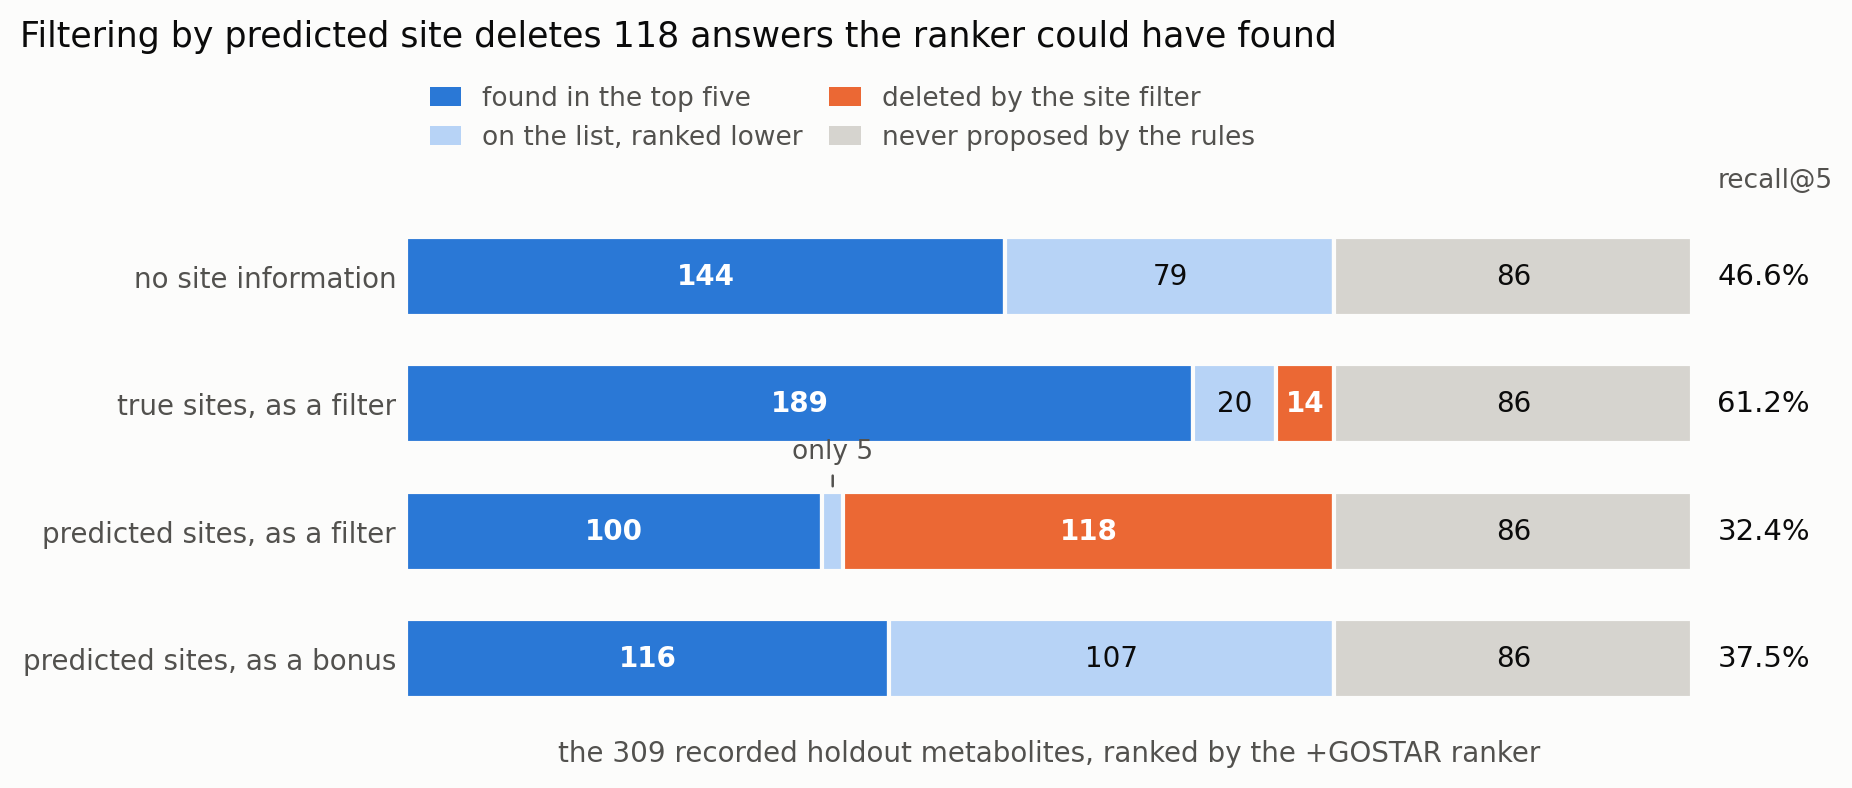

  no site information            found 144  ranked lower  79  deleted   0  never proposed  86   recall@5 46.6%
  true sites, as a filter        found 189  ranked lower  20  deleted  14  never proposed  86   recall@5 61.2%
  predicted sites, as a filter   found 100  ranked lower   5  deleted 118  never proposed  86   recall@5 32.4%
  predicted sites, as a bonus    found 116  ranked lower 107  deleted   0  never proposed  86   recall@5 37.5%

In [ ]:
# What happens to the 309 answers under each condition. Reads only files on disk, no API.
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# Same roles as every figure: blue found, pale blue on the list but ranked too low, grey never
# proposed by the rules, orange deleted by the site filter.
BLUE, PALE, NEVER, ORANGE = "#2a78d6", "#b7d3f6", "#d6d4cf", "#eb6834"
INK, MUTED, SURFACE = "#0b0b0b", "#52514e", "#fcfcfb"
res = pd.read_csv(ROOT / "SOM" / "som_results.csv").set_index("condition")["recall@5"]
N = len(test)

pred_sets = {p: set(v) for p, v in PRED["sites"].items()}
true_sets = {p: union_sites.get(p, set()) for p in sorted(set(test["parent"]))}

def in_list(site_sets):
    """Pairs whose answer is still on the candidate list after this filter."""
    n = 0
    for r in test.itertuples():
        cands = candidates.get(r.parent, {})
        kept = list(cands) if site_sets is None else [c for c, s in cands.items()
                                                      if s & site_sets.get(r.parent, set())]
        key = ev.match_key(r.metabolite, "standardized")
        n += any(ev.match_key(c, "standardized") == key for c in kept)
    return n

n_reach = in_list(None)
ROWS = [("no site information", float(res["arm 6, no site information"]), None),
        ("true sites, as a filter", float(res["true sites, union per parent"]), true_sets),
        ("predicted sites, as a filter", float(res["sites predicted by the model"]), pred_sets)]
# The same predicted sites as a score bonus large enough to put every site-matched candidate
# first: the filter's ordering without its deletions. From som_prior.ipynb, once it has run.
PRIOR = ROOT / "SOM" / "som_prior_results.csv"
if PRIOR.exists():
    prior = pd.read_csv(PRIOR)
    dominating = prior[prior["lambda"] == prior["lambda"].max()]
    ROWS.append(("predicted sites, as a bonus", float(dominating["holdout_recall5"].iloc[0]), None))
data = []
for label, r5, sets in ROWS:
    kept = in_list(sets) if sets is not None else n_reach
    found = round(r5 * N)
    data.append((label, found, kept - found, n_reach - kept, N - n_reach, r5))

fig, ax = plt.subplots(figsize=(8.3, 3.6))
fig.patch.set_facecolor(SURFACE); ax.set_facecolor(SURFACE)
for i, (label, found, low, deleted, never, r5) in enumerate(data[::-1]):
    left = 0
    for width, colour in ((found, BLUE), (low, PALE), (deleted, ORANGE), (never, NEVER)):
        ax.barh(i, width, left=left, color=colour, height=0.62, edgecolor=SURFACE, linewidth=1.5)
        if width >= 12:
            ax.text(left + width / 2, i, f"{width}", ha="center", va="center", fontsize=10,
                    color="white" if colour in (BLUE, ORANGE) else INK,
                    fontweight="bold" if colour in (BLUE, ORANGE) else "normal")
        left += width
    ax.text(N + 6, i, f"{r5:.1%}", ha="left", va="center", color=INK, fontsize=10.5)
ax.text(N + 6, len(data) - 0.35, "recall@5", ha="left", va="bottom", color=MUTED, fontsize=9.5)
# the one that needs pointing at: 5 is too small to label inside its own segment
i_pred = len(data) - 1 - [d[0] for d in data].index("predicted sites, as a filter")
_, f_, l_, *_ = data[[d[0] for d in data].index("predicted sites, as a filter")]
ax.annotate(f"only {l_}", xy=(f_ + l_ / 2, i_pred + 0.31), xytext=(0, 12), textcoords="offset points",
            ha="center", color=MUTED, fontsize=9.5,
            arrowprops=dict(arrowstyle="-", color=MUTED, linewidth=0.9))
ax.set_yticks(range(len(data)), [d[0] for d in data][::-1])
ax.set_xlim(0, N); ax.set_ylim(-0.55, len(data) - 0.2)
ax.set_xticks([])
ax.tick_params(colors=MUTED, labelsize=10, length=0)
for s in ("top", "right", "left", "bottom"): ax.spines[s].set_visible(False)
ax.legend(handles=[Patch(facecolor=BLUE, label="found in the top five"),
                   Patch(facecolor=PALE, label="on the list, ranked lower"),
                   Patch(facecolor=ORANGE, label="deleted by the site filter"),
                   Patch(facecolor=NEVER, label="never proposed by the rules")],
          loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2, frameon=False, fontsize=9.5,
          labelcolor=MUTED, handlelength=1.2, columnspacing=1.0)
deleted = data[2][3]
ax.set_title(f"Filtering by predicted site deletes {deleted} answers the ranker could have found",
             color=INK, fontsize=12.5, loc="left", pad=46, x=-0.3)
ax.set_xlabel(f"the {N} recorded holdout metabolites, ranked by the +GOSTAR ranker",
              color=MUTED, fontsize=10)
plt.savefig(ROOT / "docs" / "som_comparison.png", dpi=200, bbox_inches="tight", facecolor=SURFACE)
plt.show()
for label, found, low, deleted, never, r5 in data:
    print(f"  {label:<30} found {found:>3}  ranked lower {low:>3}  deleted {deleted:>3}  "
          f"never proposed {never:>3}   recall@5 {r5:.1%}")